# A converged, voltage-stable 315 kV model of the Québec grid
### Progress report for Prof. Xiaozhe Wang — ECSE 458 capstone, meeting of November 17, 2026

**Team:** Jean Flichy, Jana Alameddine, Etienne Guégan, Panayiotis Saropoulos · **Base model:** Nathan Guan's PyPSA-Earth model of the Hydro-Québec grid (`nathan103004/quebec-pypsa-earth`)

**How to read this notebook.** Every number shown in a code cell is recomputed from the files in `data/` (written by `make_results.py`, which rebuilds the model from Nathan's `elec_solved.nc` and `elec_full.nc`). The markdown summarizes; the code cells are the evidence. Section 9 answers two questions we keep asking ourselves (*is a model without exact data useful?* and *why not just add infinite SVCs?*). Section 10 is the plan.

> **AI use.** Most of the code and diagnostics below were produced with Claude (Anthropic) under Jean's direction, on two nights (Nov. 16-17), and then reviewed by a second Claude model acting as a critical reviewer. The team has not yet re-derived every step by hand: **that is precisely our next step** (Section 10). We present this as a *map of the problems and their fixes*, not as a finished model.

## TL;DR

1. **We found the main reason the AC power flow did not converge:** PyPSA-Earth measures line lengths in **Web Mercator (EPSG:3857)**, which stretches distances by 1/cos(latitude). Every line in the model is **41 % to 66 % too long**, so every series reactance *x* and every shunt susceptance *b* is too large. 735 kV: the OSM lines measure 19,565 km in PyPSA-Earth against 12,957 km for the same routes measured on the ellipsoid, and **12,581 km declared by Hydro-Québec**. After our correction the 315 kV network has 5,281 km (Nathan's: 8,216 km) against **5,509 km (HQ)**.
2. **With real lengths and realistic reactive power** (Q limits on every machine, the 12 real HQ SVCs / synchronous condensers, switchable shunt reactors and capacitor banks, 40 % series compensation on the 8 real corridors), the 315 kV model **converges for 168/168 hours of the test week, with every machine inside its Q limits and every bus inside 0.95-1.05 pu**. Nathan's model needed unlimited reactive power; Etienne's version converged 162/168 hours with voltages up to 1.62 pu.
3. **A critical review then found one more problem**, and it was not in the physics: the LOPF gives all hydro a zero cost, so it was free to shut down 3.4 GW of southern run-of-river plants (Beauharnois, Carillon...) at the peak. The peak-hour solution was then on the **unstable branch** of the P-V curve. Giving run-of-river plants dispatch priority (one line of code) fixes it: **168/168 hours voltage-stable, load margin +7 % at the peak** (+10 % with a Kron equivalent of the southern sub-transmission network).
4. **The margin is still far below reality** (the real grid carried 43.1 GW on Feb. 3, 2023: +23 % over our peak). The remaining gap points to data we do not have: reactive compensation in the south, the real allocation of loads to substations, and losses counted twice.
5. **Next:** rebuild the model ourselves, step by step from OpenStreetMap, with every assumption documented and checked against Hydro-Québec aggregates; then AC-CFM cascades under climate hazards.

In [1]:
import os, warnings, logging
warnings.filterwarnings("ignore"); logging.getLogger("pypsa").setLevel(logging.ERROR)
import numpy as np, pandas as pd
import figs as F                     # all figures (figs.py, same folder)
from IPython.display import display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
d = F.load_data()
w1, w2 = d["w1"], d["w2"]
def crit(w):
    ok = w.converged.astype(bool)
    return {"Newton converges": int(w.newton_ok.sum()) if "newton_ok" in w else int(len(w)), "within Q limits": int(ok.sum()),
            "all V in 0.90-1.10": int((w.in_hard.astype(bool) & ok).sum()), "all V in 0.95-1.05": int((w.in_band.astype(bool) & ok).sum()),
            "voltage-stable": int(w.stable.sum()), "V min": round(w.v_min.min(), 3), "V max": round(w.v_max.max(), 3)}
display(pd.DataFrame({"v1 (Nov. 16-17 night)": crit(w1), "v2 (v1 + run-of-river priority)": crit(w2)}).T)

,Newton converges,within Q limits,all V in 0.90-1.10,all V in 0.95-1.05,voltage-stable,V min,V max
v1 (Nov. 16-17 night),168.0,168.0,168.0,165.0,167.0,0.922,1.035
v2 (v1 + run-of-river priority),168.0,168.0,168.0,168.0,168.0,0.965,1.037


## 1. Where we were on November 3, and what you asked

At our last meeting we showed that Nathan's 735 kV model "converged" only because its generators were allowed **unlimited reactive power** (22 to 51 GVAr absorbed in total, up to 8 GVAr at a single 73 MW plant), and that the 315 kV model converged for **0 to 3 hours of 168**. We also noticed that the 735 kV network had about **1.6 times too many kilometres** compared with Hydro-Québec's inventory, without knowing why.

Your guidance was:
1. **make the AC model converge, as low in voltage as feasible** — a converged 315 kV model is a good target;
2. **study the model's assumptions in depth** — what is wrong, what to correct, add or remove — and understand the model well enough to explain it orally;
3. then feed the AC model into **AC-CFM** with climate-driven fragility curves (open question: which climate data to use).

This notebook reports on points 1 and 2. Since then, Etienne independently reached 161-162 converged hours (Nov. 14) with Nathan's corrections plus series compensation and fixed shunts, but with unlimited Q and voltages up to 1.62 pu.

## 2. What we learned (PyPSA course and model study)

Jean wrote, with Claude, a structured self-study course (*Le réseau québécois, de Maxwell à PyPSA*: 16 chapters from phasors and line parameters to Newton-Raphson, continuation, DC/LOPF duality, and a dissection of Nathan's pipeline) and is working through it. The points below are the ones that changed how we read the model.

### 2.1 The LOPF decides, the AC power flow checks
The LOPF (linear optimal power flow) is a DC approximation: $|V| = 1$, no reactive power, no losses, $P_{ij} \approx (\theta_i - \theta_j)/x_{ij}$. It always has a solution and decides *who produces*. The AC power flow solves the full nonlinear equations
$$P_i = \sum_k |V_i||V_k|\,(G_{ik}\cos\theta_{ik} + B_{ik}\sin\theta_{ik}), \qquad Q_i = \sum_k |V_i||V_k|\,(G_{ik}\sin\theta_{ik} - B_{ik}\cos\theta_{ik})$$
for that dispatch; it decides nothing and may have **no solution**. In Nathan's pipeline (and ours) the dispatch is computed once by the LOPF, then imposed on the AC power flow. **Consequence we learned the hard way (Section 6): if the LOPF picks a dispatch that the AC physics cannot carry, no amount of Newton tuning helps.**

### 2.2 "Newton converges" is not a sufficient criterion
A PV bus holds its voltage with whatever reactive power it takes. If Q is unlimited, almost any network "converges" (see Section 9.2). We therefore define **converged = Newton converges AND every machine/SVC within its Q limits AND every bus within 0.90-1.10 pu**, and after the review we add **AND voltage-stable** ($\partial V_i/\partial Q_i > 0$ at every load bus, i.e. all eigenvalues of the reduced Jacobian $J_R = \partial Q/\partial V$ positive — the V-Q sensitivity criterion of Gao, Morison & Kundur, 1992). In every one of our 16 sensitivity variants, Newton converged 168/168 hours: the criterion that discriminates is never convergence itself.

### 2.3 Reactive power is *the* problem of a long-line 735 kV grid
- A 735 kV line generates reactive power through its capacitance: about **2.6 MVAr per km** in our model, i.e. ~41 GVAr for the whole 735 kV network at 1 pu.
- It absorbs $I^2X$ in its series reactance. Below the surge-impedance loading (~2,000 MW per 735 kV circuit) a line is a net source of reactive power (night: overvoltages, the Ferranti effect); above it, a net sink (peak: undervoltages).
- This is why Hydro-Québec built **series compensation** (35-40 % on its long corridors), **switchable shunt reactors**, **SVCs** and **synchronous condensers**. A model without them either diverges or "converges" with unrealistic generator Q.

### 2.4 Voltage stability and the P-V curve
As load grows, voltages fall slowly, then collapse at the "nose" of the P-V curve, where the Jacobian becomes singular. Beyond the nose there is no solution; just before it, Newton can land on the **lower branch**, a mathematically valid but physically unstable solution. A PV→PQ switch (a machine reaching its Q limit) can move the nose sharply to the left. This is the mechanism behind our peak-hour problem.

### 2.5 Kron reduction
Eliminating a passive sub-network exactly: $Y_{eq} = Y_{bb} - Y_{be} Y_{ee}^{-1} Y_{eb}$. Nathan's reduction to 315 kV *deleted* the < 315 kV network (and moved its loads to the nearest ≥ 315 kV bus); 20 of the 58 735 kV substations lost their transformation. We put back exact equivalents of the < 315 kV network around Montréal and Saguenay.

### 2.6 PyPSA traps that cost us time
- `Generator.p_set` that is not NaN freezes the dispatch inside `optimize()` (PyPSA 1.3).
- The < 315 kV line types in PyPSA-Earth are **50 Hz** pandapower types: $x$ and $b$ are 17 % too low at 60 Hz.
- The LOPF optimum is **degenerate** (many dispatches with the same cost): even the *order* in which lines are added changed the result. We fixed the order, but the real fix is a physical tie-break (Section 6).

## 3. Root cause: line lengths measured in Web Mercator

PyPSA-Earth builds the OSM network in `scripts/build_osm_network.py` with
```python
df_l["length"] = df_l.to_crs(distance_crs).geometry.length      # distance_crs: EPSG:3857 in config.default.yaml
```
EPSG:3857 is the Web Mercator projection of Google Maps / OpenStreetMap tiles. It is conformal, not equidistant: lengths are stretched by $1/\cos\varphi$, i.e. **×1.41 at Montréal (45.5° N), ×1.66 at James Bay (53° N)**. PyPSA-Earth's documentation recommends this value for distance measurements. At the latitudes of most PyPSA-Earth countries the error is small; in Québec it is large. Since $r$, $x$, $b$ (and Nathan's St Clair ratings) are all proportional to length, **every line had ~50 % too much series reactance and ~50 % too much charging**: the network was both too weak (angles, voltage drops) and too capacitive (night overvoltages). That is why Nathan's 735 kV model needed 70 % series compensation and why the 315 kV model would not converge.

**Evidence** (below): for almost every line, *stored length / geodesic length of the same OSM geometry* falls exactly on $1/\cos(\text{latitude})$; points below the curve are lines whose stored length was corrected later or whose geometry is incomplete.

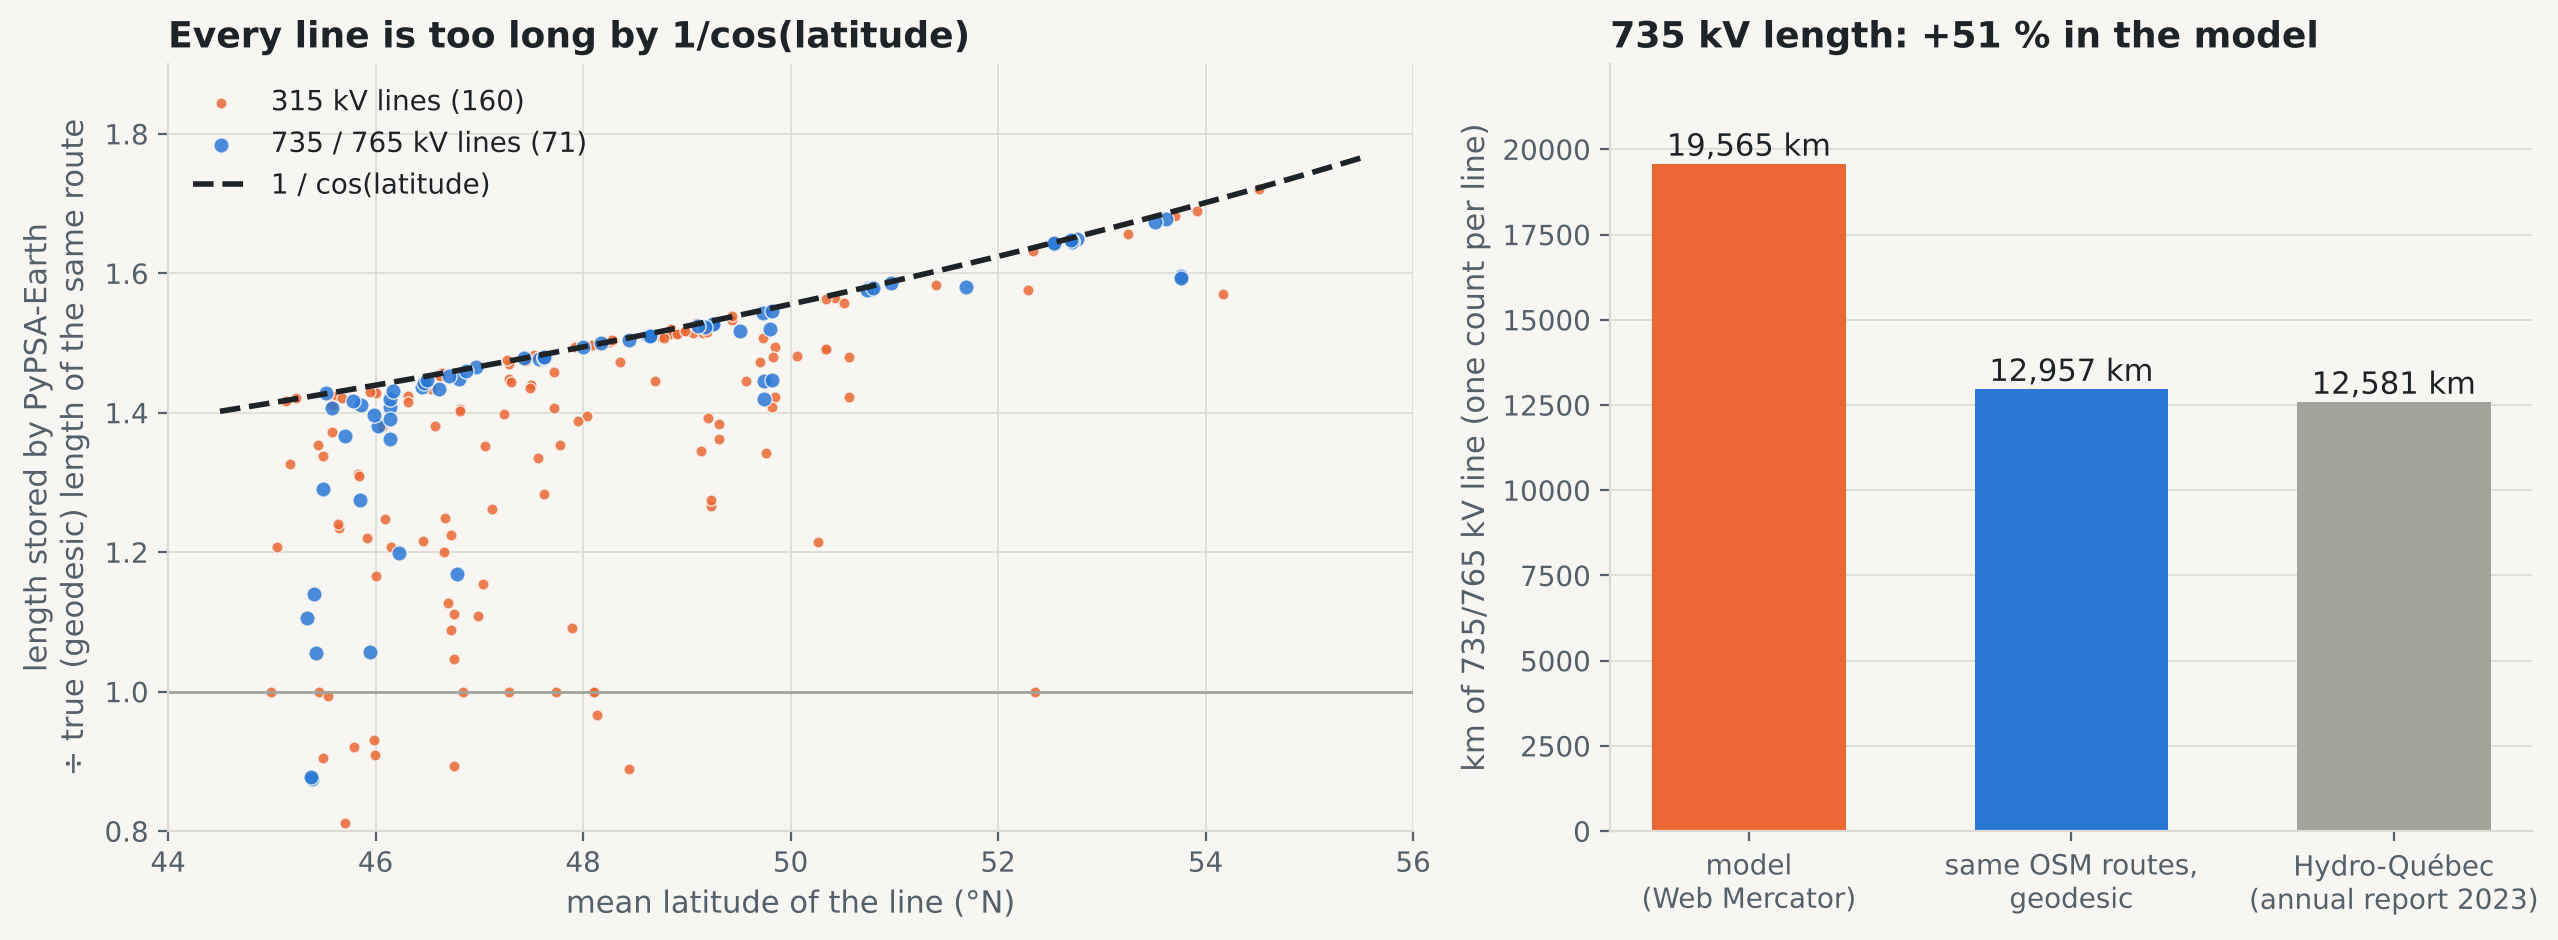

In [2]:
F.fig_mercator(d["T"]);

In [3]:
# Kilometres of line, model vs Hydro-Québec ("Nos équipements": 12,581 km at 765/735 kV, 5,509 km at 315 kV)
import pypsa
v2net = pypsa.Network("data/reseau_315kv_v2.nc")
src = pypsa.Network(os.path.join("..", "..", "..", "network", "networks_current", "elec_solved.nc")) if os.path.exists(os.path.join("..", "..", "..", "network", "networks_current", "elec_solved.nc")) else None
def km(net):
    L = net.lines[(net.lines.length > 0) & ~net.lines.index.str.startswith("KRON")]
    return {"735/765 kV, km of line": round(L.length[L.v_nom >= 700].sum()), "315 kV, km of line": round(L.length[L.v_nom == 315].sum())}
rows = {"Hydro-Québec (Nos équipements)": {"735/765 kV, km of line": 12581, "315 kV, km of line": 5509}}
if src is not None: rows["Nathan's elec_solved.nc (Web Mercator)"] = km(src)
rows["our model after E1 (geodesic)"] = km(v2net)
display(pd.DataFrame(rows).T)
print("Note: the model's 735 kV total includes the 3 Churchill Falls-Montagnais lines (~690 km, in Labrador), which HQ's figure does not.")

,"735/765 kV, km of line","315 kV, km of line"
Hydro-Québec (Nos équipements),12581,5509
Nathan's elec_solved.nc (Web Mercator),20243,8216
our model after E1 (geodesic),12696,5281


Note: the model's 735 kV total includes the 3 Churchill Falls-Montagnais lines (~690 km, in Labrador), which HQ's figure does not.


**Correction rule (E1).** If the OSM route is reliable (ends within 5 km of the buses, sinuosity route/straight line between 1.0 and 1.6), the length is the **geodesic length of the route**; otherwise it is the **straight-line distance × 1.084** (median sinuosity of the reliable routes). A first method (stored length × geodesic/Mercator ratio of the route) was abandoned because it made some lines shorter than the straight line between their ends. The review checked the final network: all 273 lines lie between 1.00 and 1.60 times the straight-line distance.

**This probably affects other PyPSA-Earth models at high latitude** (and every network in our repository, including Nathan's 735 kV). We think it is worth reporting to Nathan and upstream, with credit to his model.

## 4. The corrected model, step by step (v1)

Each step is one function in `../reseau_315kv/reseau315.py`. *Before* = the assumption we inherited; *after* = what we use now and why.

| Step | Before (inherited) | After (v1) | Why / source |
|---|---|---|---|
| **E1** line lengths | OSM geometry measured in Web Mercator | geodesic route length, or straight line × 1.084 | Section 3; HQ inventory |
| **E2** Churchill Falls | 3 OSM lines **plus** 3 lines added by a script for the same corridor (6 circuits) | 3 circuits, plant moved to the real OSM substation | same corridor counted twice |
| **E2b** Kron equivalents | < 315 kV network deleted, loads moved to nearest bus | exact Kron equivalents of the < 315 kV network around Montréal (54 buses → 81 branches) and Saguenay (41 → 3) | 20 of 58 735 kV substations had lost their transformation |
| **E3** circuit counts | Nathan's sending-end correction (3 circuits on 5 corridors) | kept (questioned by the review, Section 7) | OSM under-counts parallel circuits |
| **E4** series compensation | 70 % on 15 "long / high-angle" lines | **40 % on the 8 real HQ corridors** (19 lines) | Régie de l'énergie D-2016-122: platforms compensate "about 35 % to 40 %" |
| **E5** LOPF ratings | 3 × St Clair curve | 3 × St Clair with true lengths, capped by the static stability limit $(V^2/x)\sin 40°$ | line 3360 (Romaine) was dispatched at 90 % of $V^2/x$ |
| **E6** reactive power | unlimited Q at PV buses | Q limits on every machine (hydro −0.30 / +0.48 × p_nom, wind ±0.33); the **12 real SVCs / synchronous condensers** (Régie R-3712-2009 and others); switchable line reactors (42 GVAr at full use); switchable capacitor banks at load substations (Q of the peak load, 10.8 GVAr); loads at cos φ 0.95; voltage set-point 1.02 pu | HQ practice; this is what the real grid has |
| **E7** solving | one `n.pf()` call | Newton-Raphson hour by hour with PV→PQ switching at Q limits, and an operator-like logic that switches reactors/capacitors to keep SVC reserve; validated against PyPSA's and pandapower's solvers | Q limits need an outer loop |

The 12 SVCs / synchronous condensers in the model:

In [4]:
import sys; sys.path.insert(0, os.path.join("..", "reseau_315kv"))
try:
    import reseau315 as R
    D = R.reactive_devices_table().rename(columns={"poste": "substation", "nombre": "units", "qmin_unit": "Qmin/unit (MVAr)", "qmax_unit": "Qmax/unit (MVAr)"})
    D["source"] = D.source.str.replace("supposée", "assumed").str.replace("supposés", "assumed").str.replace("tableau", "table").str.replace("puissance", "rating").str.replace("nombre et", "number and").str.replace("chacun", "each")
    display(D)
    print(f"Total: +{(D.units * D['Qmax/unit (MVAr)']).sum():.0f} / {(D.units * D['Qmin/unit (MVAr)']).sum():.0f} MVAr")
except Exception as e:
    print("reseau315 not importable here:", e)

,substation,bus,type,units,Qmin/unit (MVAr),Qmax/unit (MVAr),source
0,Albanel,345,SVC,2,-105,300,"Régie R-3712-2009, table 2"
1,Chamouchouane,286,SVC,2,-300,300,Régie R-3712-2009 ; Hitachi Energy (±330)
2,Chibougamau,310,SVC,2,-105,300,Régie R-3712-2009
3,Laurentides,25,SVC,1,-100,350,Régie R-3712-2009
4,Némiscau,457,SVC,2,-105,300,Régie R-3712-2009
5,La Vérendrye,308,SVC,2,-105,300,Régie R-3712-2009 ; R-4125-2020 (-100/+300)
6,Lévis (déglaceur),148,SVC,1,-125,250,Régie R-3712-2009
7,Chénier,136,SVC,2,-300,300,"Hitachi Energy (2011, ±300 each)"
8,Lévis,148,CS,2,-200,300,Régie D-2005-45 (-200/+300 each)
9,Duvernay,195,CS,3,-200,300,3 CS (Régie R-3876-2014) ; rating assumed = Lévis


Total: +6600 / -3865 MVAr


## 5. Results

### 5.1 Scorecard across the milestones

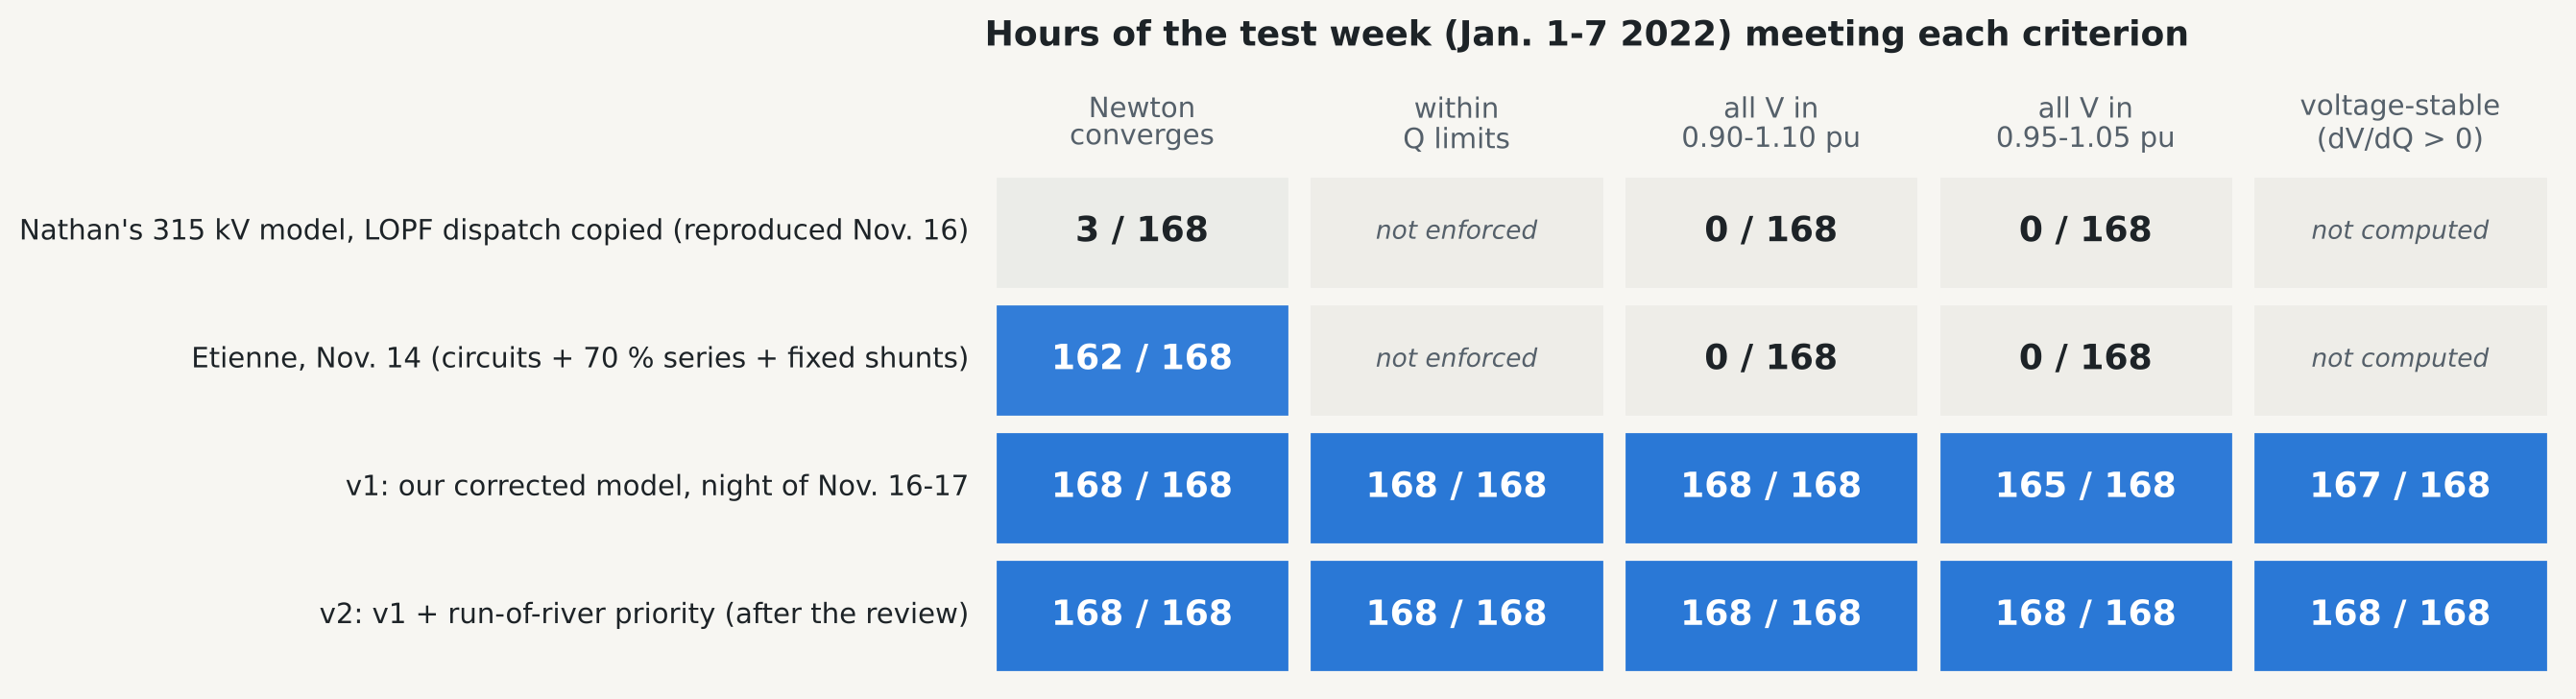

In [5]:
F.fig_scorecard();

### 5.2 The test week (Jan. 1-7, 2022; 168 hours; peak 34.96 GW on Jan. 3 at 17:00)
v2 keeps every bus inside 0.95-1.05 pu at every hour. In v1 the lowest voltage dipped to 0.922 pu at the peak (bus 800, Montréal-West) — and that solution turned out to be unstable (Section 6).

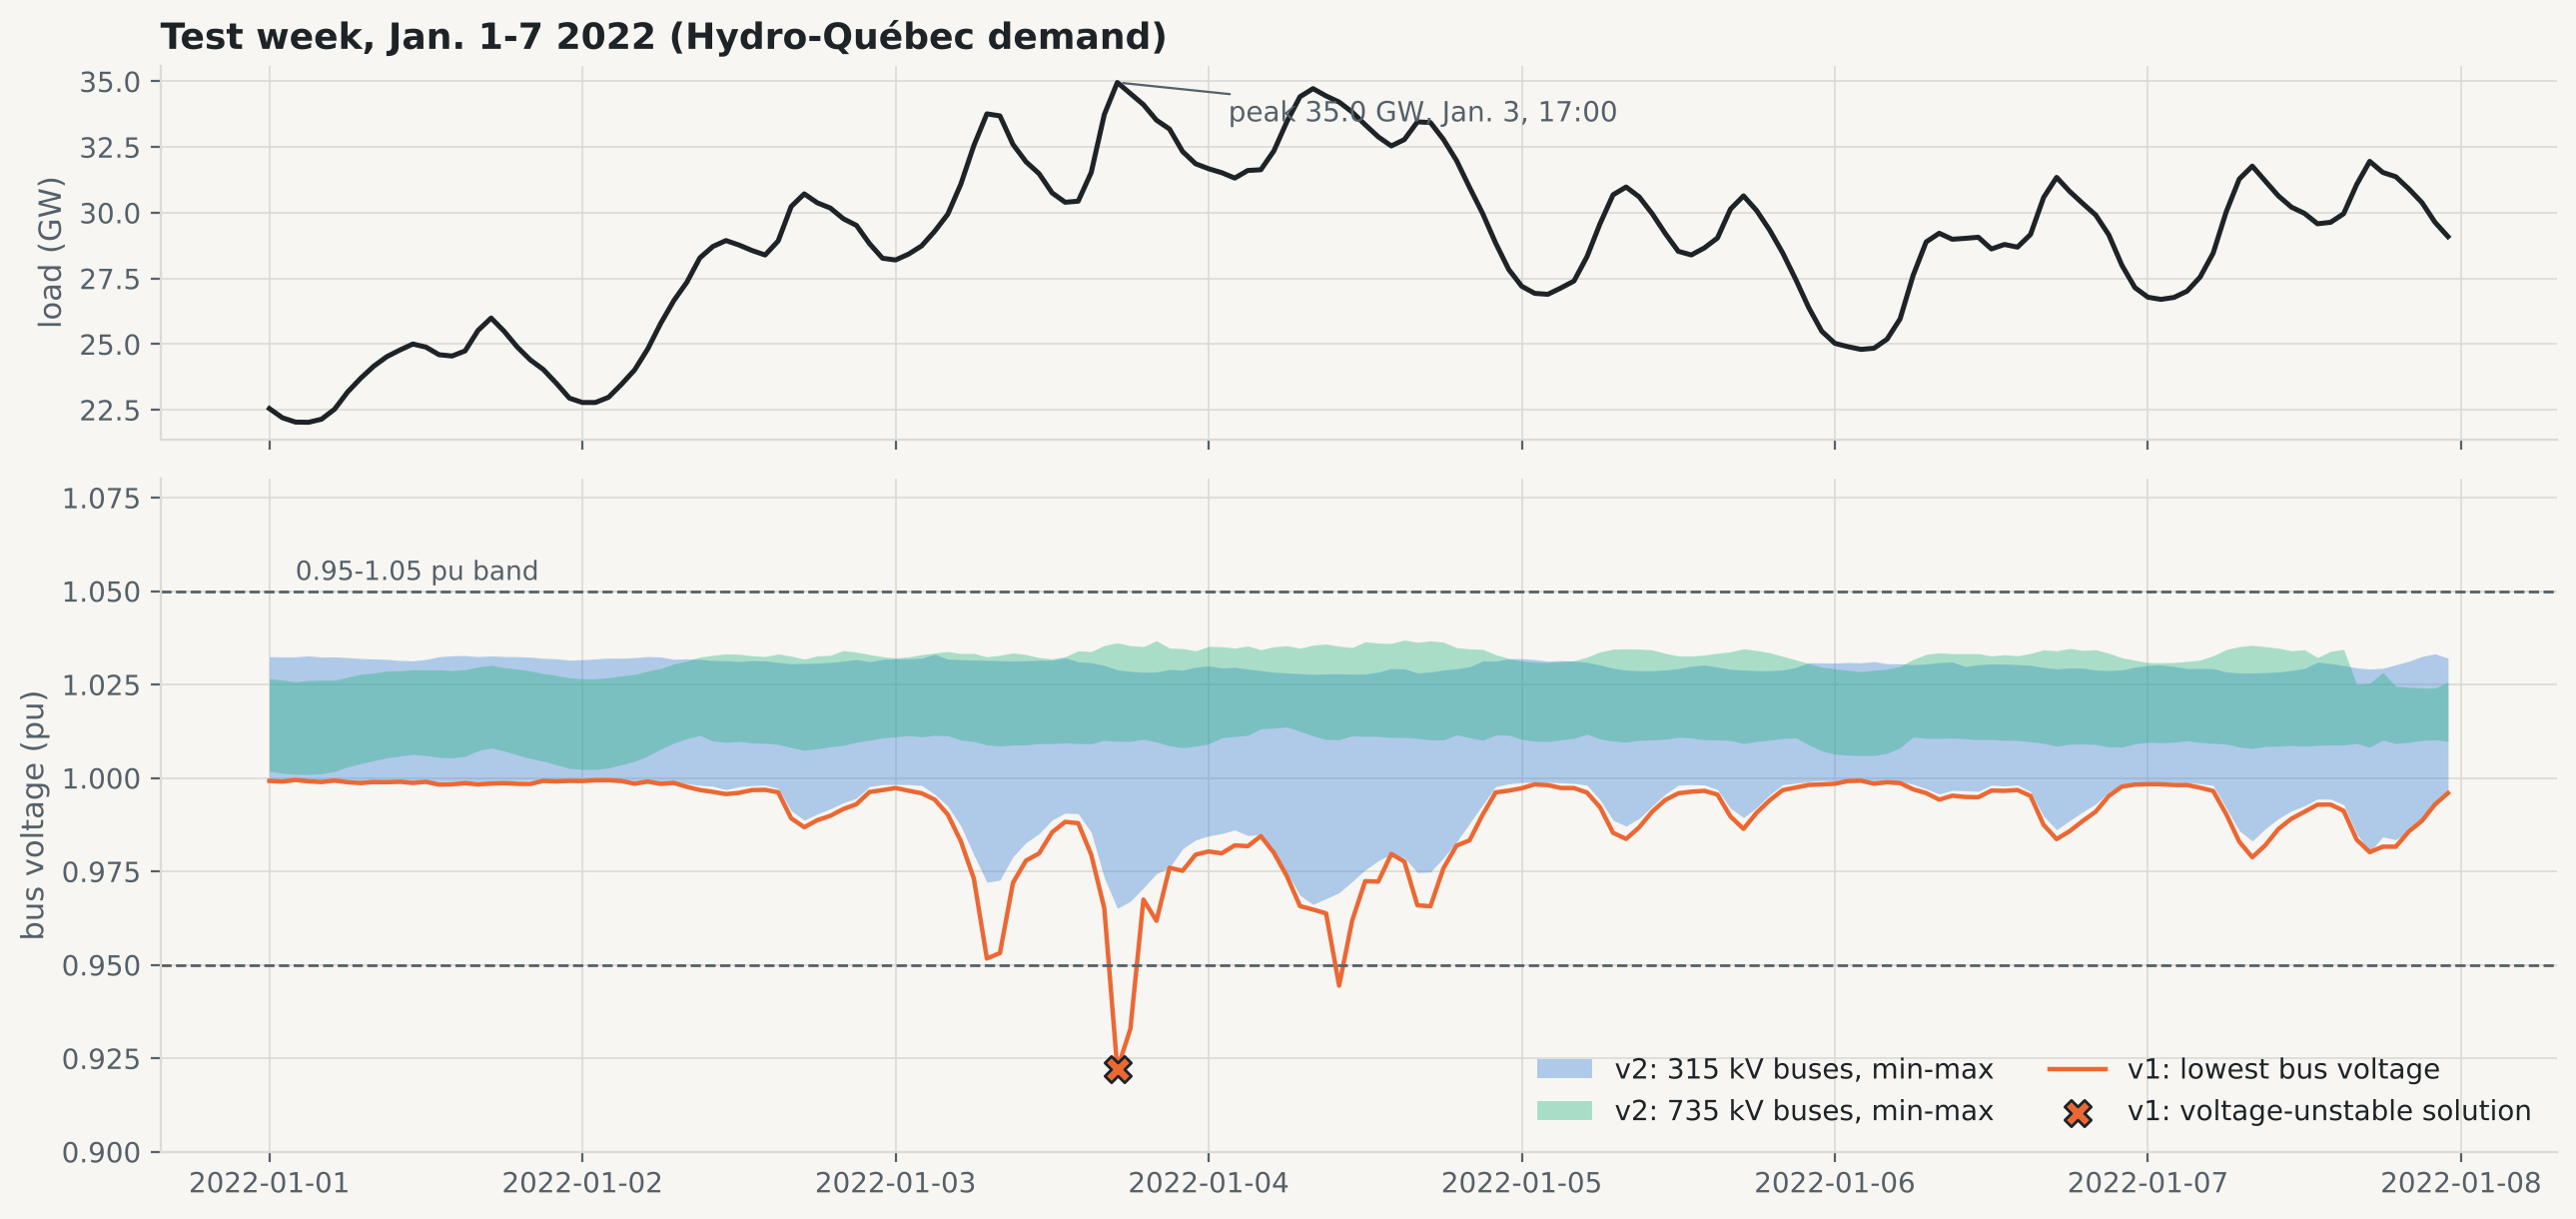

In [6]:
F.fig_week(d["w1"], d["w2"], d["V2"], d["buses"]);

### 5.3 Where the voltages are at the peak
The weak zone is the west of Montréal: it is at the end of ~1,000 km of transmission from James Bay and Churchill Falls, and its local reactive sources (Chénier and Duvernay SVC/condensers, Beauharnois) are at their limits.

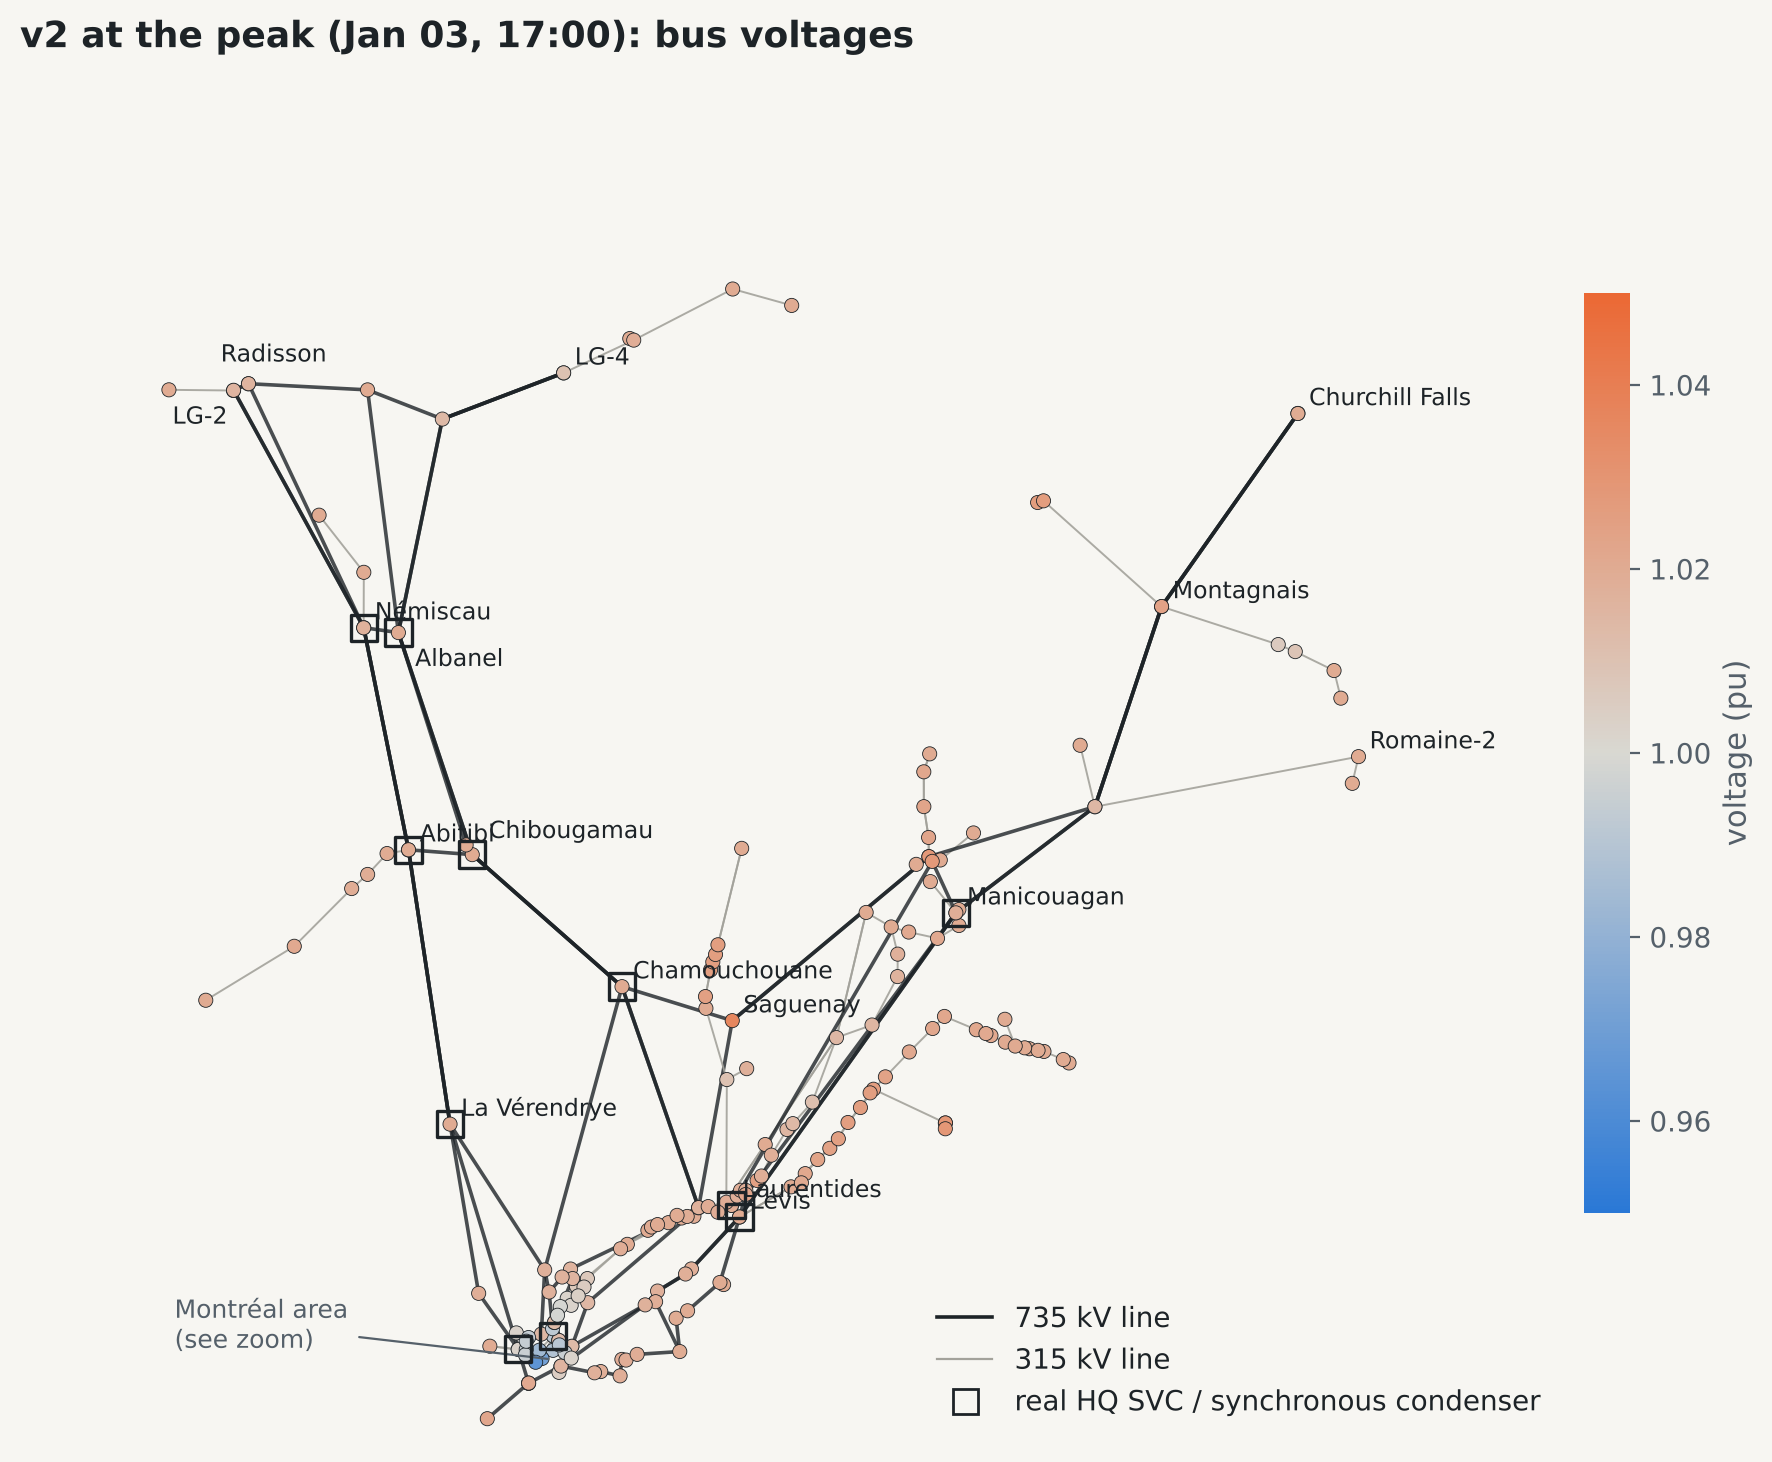

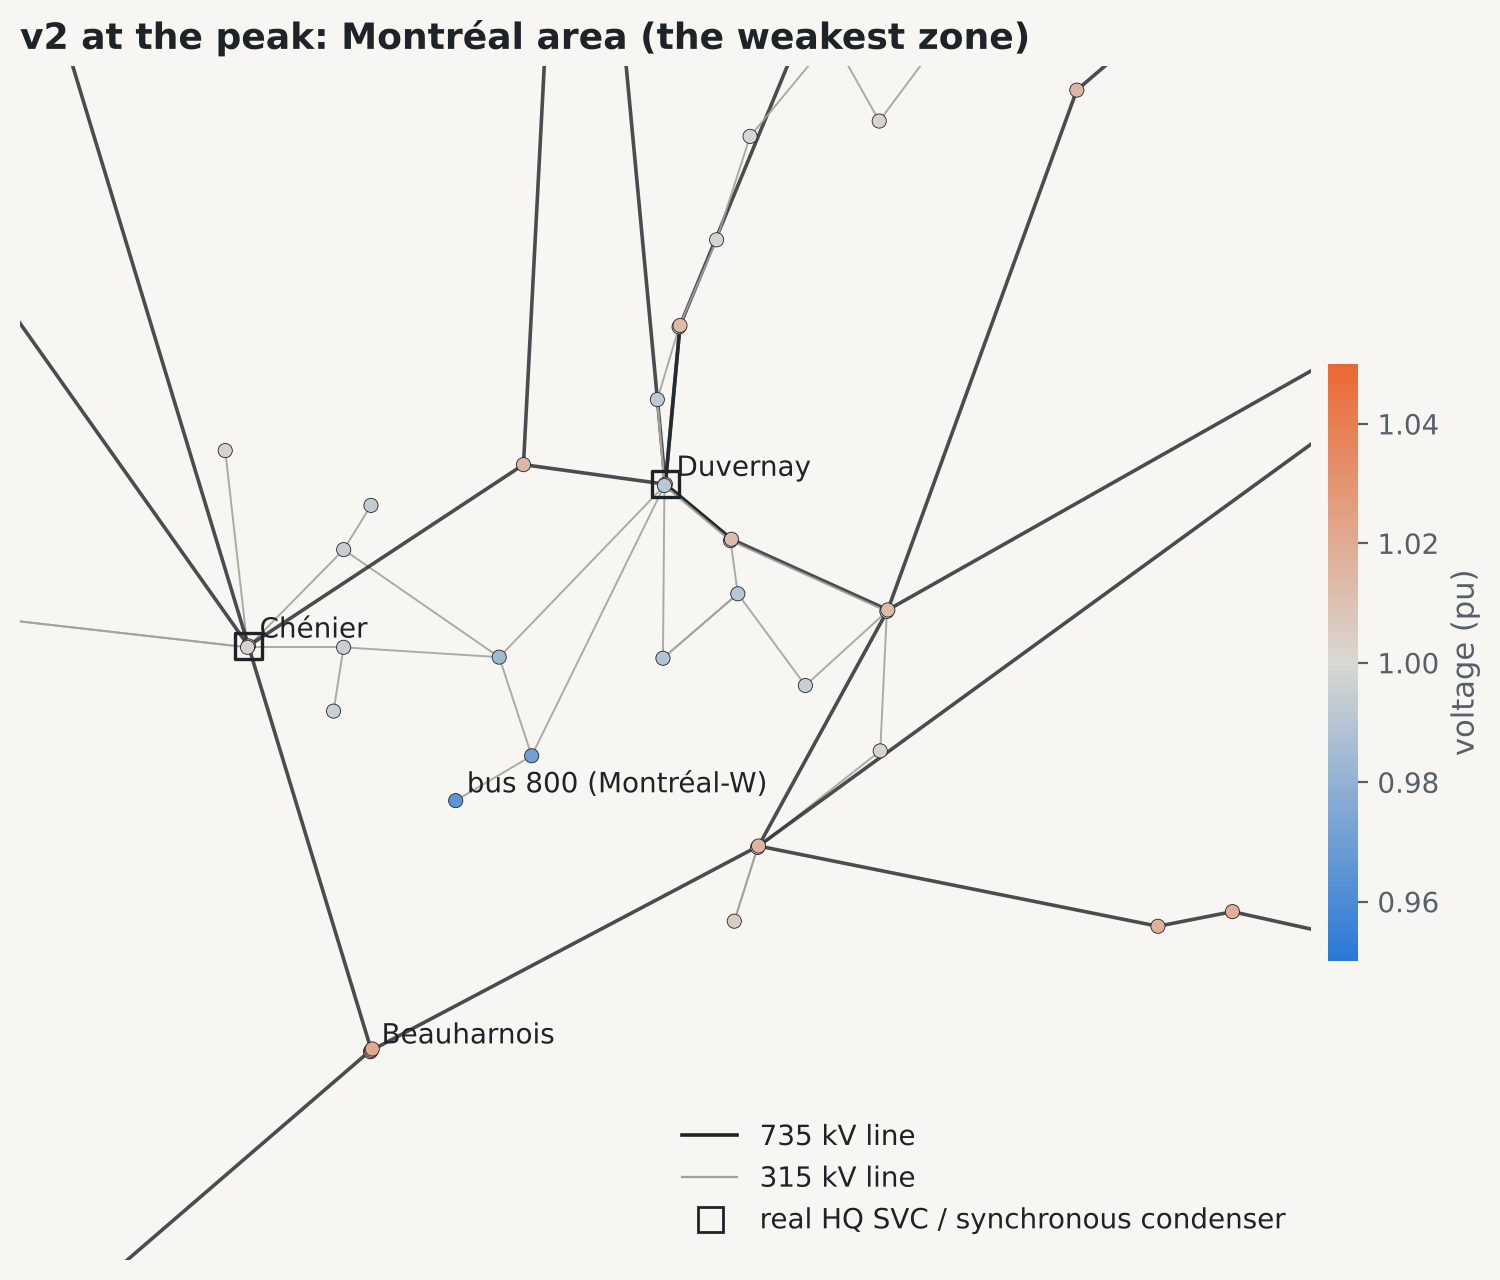

In [7]:
F.fig_map("data/reseau_315kv_v2.nc", d["V2"]);
F.fig_map("data/reseau_315kv_v2.nc", d["V2"], box=(-74.3, -72.9, 45.15, 46.0), title="v2 at the peak: Montréal area (the weakest zone)");

### 5.4 Three solvers agree
The hour-by-hour solutions come from our own Newton-Raphson (needed to switch Q limits and shunts thousands of times). Every hour of v1 was re-solved by PyPSA's solver from a cold start and by pandapower (exported through MATPOWER format): identical within $10^{-7}$ pu. For v2, the peak and the lightest hour were re-checked the same way:

In [8]:
display(pd.read_csv("data/v2_validation_pypsa.csv", index_col=0).rename(columns={"pypsa_converge": "PyPSA converges", "ecart_V_max": "max |ΔV| vs our solver (pu)", "ecart_angle_deg_max": "max |Δθ| (deg)"}))
pp = pd.read_csv("data/v2_validation_pandapower_peak.csv", index_col=0).iloc[:, 0]
print(f"pandapower at the peak: converges {pp['converge_etat_fige']}, machines outside Q limits {pp['bus_PV_hors_limites']}, "
      f"re-check with pandapower's own Q-limit enforcement {pp['converge_limites_Q_pandapower']}, max |ΔV| {float(pp['max_dV_vs_engine']):.1e} pu")
print("MATPOWER case of the v2 peak for AC-CFM: data/quebec_315kv_v2_peak.m")

,PyPSA converges,max |ΔV| vs our solver (pu),max |Δθ| (deg)
snapshot,,,
2022-01-03 17:00:00,True,9.160763e-09,6.091430e-07
2022-01-01 03:00:00,True,3.146989e-09,2.040421e-07


pandapower at the peak: converges True, machines outside Q limits 0, re-check with pandapower's own Q-limit enforcement True, max |ΔV| 9.2e-09 pu
MATPOWER case of the v2 peak for AC-CFM: data/quebec_315kv_v2_peak.m


### 5.5 Sanity checks against Hydro-Québec aggregates

In [9]:
ld = pd.read_csv("data/load_GW.csv", index_col=0, parse_dates=True).iloc[:, 0]
pk = F.PEAK
rows = [
    ("AC losses at the peak (MW, % of load)", f"{w2.p_slack[pk]:.0f} MW = {100 * w2.p_slack[pk] / (ld[pk] * 1e3):.1f} %", "the LOPF is lossless: all losses appear at the slack bus"),
    ("Shunt reactors switched in at the peak", f"{w2.q_react_MVAr[pk] / 1e3:.1f} GVAr", "HQ (1996): ~11 GVAr in service at peak, 25.5 GVAr installed"),
    ("Shunt reactors switched in, max of the week (night)", f"{w2.q_react_MVAr.max() / 1e3:.1f} GVAr", "above HQ's 25.5 GVAr installed: too much line charging remains (E3?)"),
    ("Machines at a Q limit (mean / max)", f"{w2.n_pq.mean():.1f} / {int(w2.n_pq.max())} of 61", ""),
    ("Load shedding in the LOPF", "0 %", ""),
]
display(pd.DataFrame(rows, columns=["check", "v2", "comment"]))

,check,v2,comment
0,"AC losses at the peak (MW, % of load)",1465 MW = 4.2 %,the LOPF is lossless: all losses appear at the slack bus
1,Shunt reactors switched in at the peak,16.5 GVAr,"HQ (1996): ~11 GVAr in service at peak, 25.5 GVAr installed"
2,"Shunt reactors switched in, max of the week (night)",33.8 GVAr,above HQ's 25.5 GVAr installed: too much line charging remains (E3?)
3,Machines at a Q limit (mean / max),11.1 / 15 of 61,
4,Load shedding in the LOPF,0 %,


## 6. The review: v1's peak hour was voltage-unstable, and the cause was the dispatch

After v1 we asked a second model to review the work critically (`../revue_fable/RAPPORT.md`). Its main findings:

1. **The v1 solution at the peak is on the unstable branch of the P-V curve.** At 59 load buses, injecting reactive power *lowers* the voltage ($\partial V/\partial Q < 0$); one eigenvalue of $J_R$ is negative. Newton converged, Q limits were respected, voltages were in 0.90-1.10 pu — and yet it is not an operating point. The other 167 hours are stable. (This also explained an odd result: the Beauharnois regulator sat at its Q maximum with a voltage *above* its set-point.)
2. **Why:** the LOPF gives every hydro plant a zero marginal cost, so reservoirs in the north and run-of-river plants in the south are interchangeable, and the solver picked a dispatch that **shut down 3.4 GW of southern run-of-river** (Beauharnois 1.8 GW, Carillon, Paugan, Chelsea...) at the peak. That power then came from James Bay, ~1,000 km away, and the reactive power of the idle southern machines was still counted. Four random 0.1 % perturbations of the costs all gave a better dispatch: v1 had landed on the worst of five equally cheap optima.
3. **Fix (v2):** run-of-river plants get a marginal cost of −0.2 \$/MWh (they cannot store water; the model already does this for wind at −0.1). This is an operating rule, not a tuning knob.

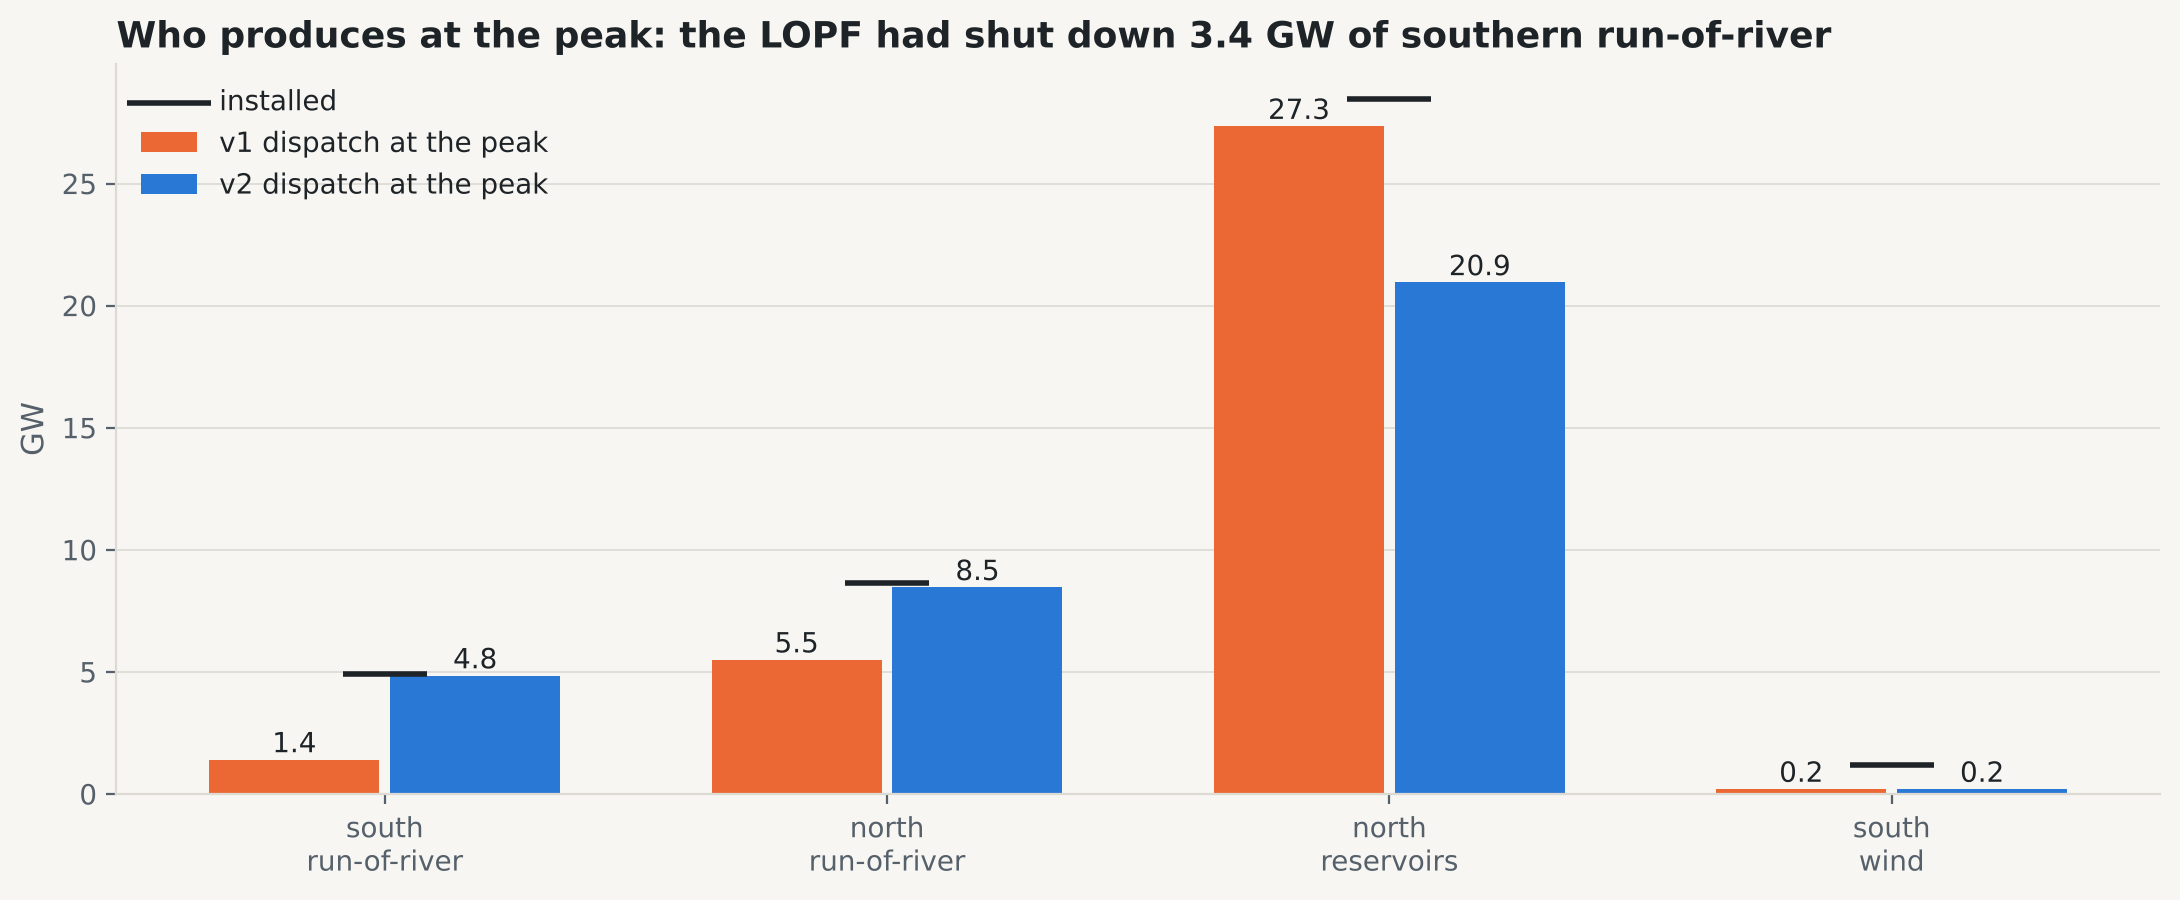

In [10]:
F.fig_dispatch(d["disp"]);

### 6.1 Load margin at the peak
Load and generation of the peak hour are scaled together, shunts are re-dispatched at each step, Q limits are enforced, and each point is tested for voltage stability.

v1: last stable point at the peak: none (the peak itself is unstable)
v2: last stable point at the peak: λ = 1.07 (37.4 GW)
v2 + Kron equivalent of the whole southern < 315 kV network (Québec buses only): λ = 1.10 (38.5 GW)
Real grid: 43.1 GW on Feb. 3, 2023 → λ ≥ 1.23


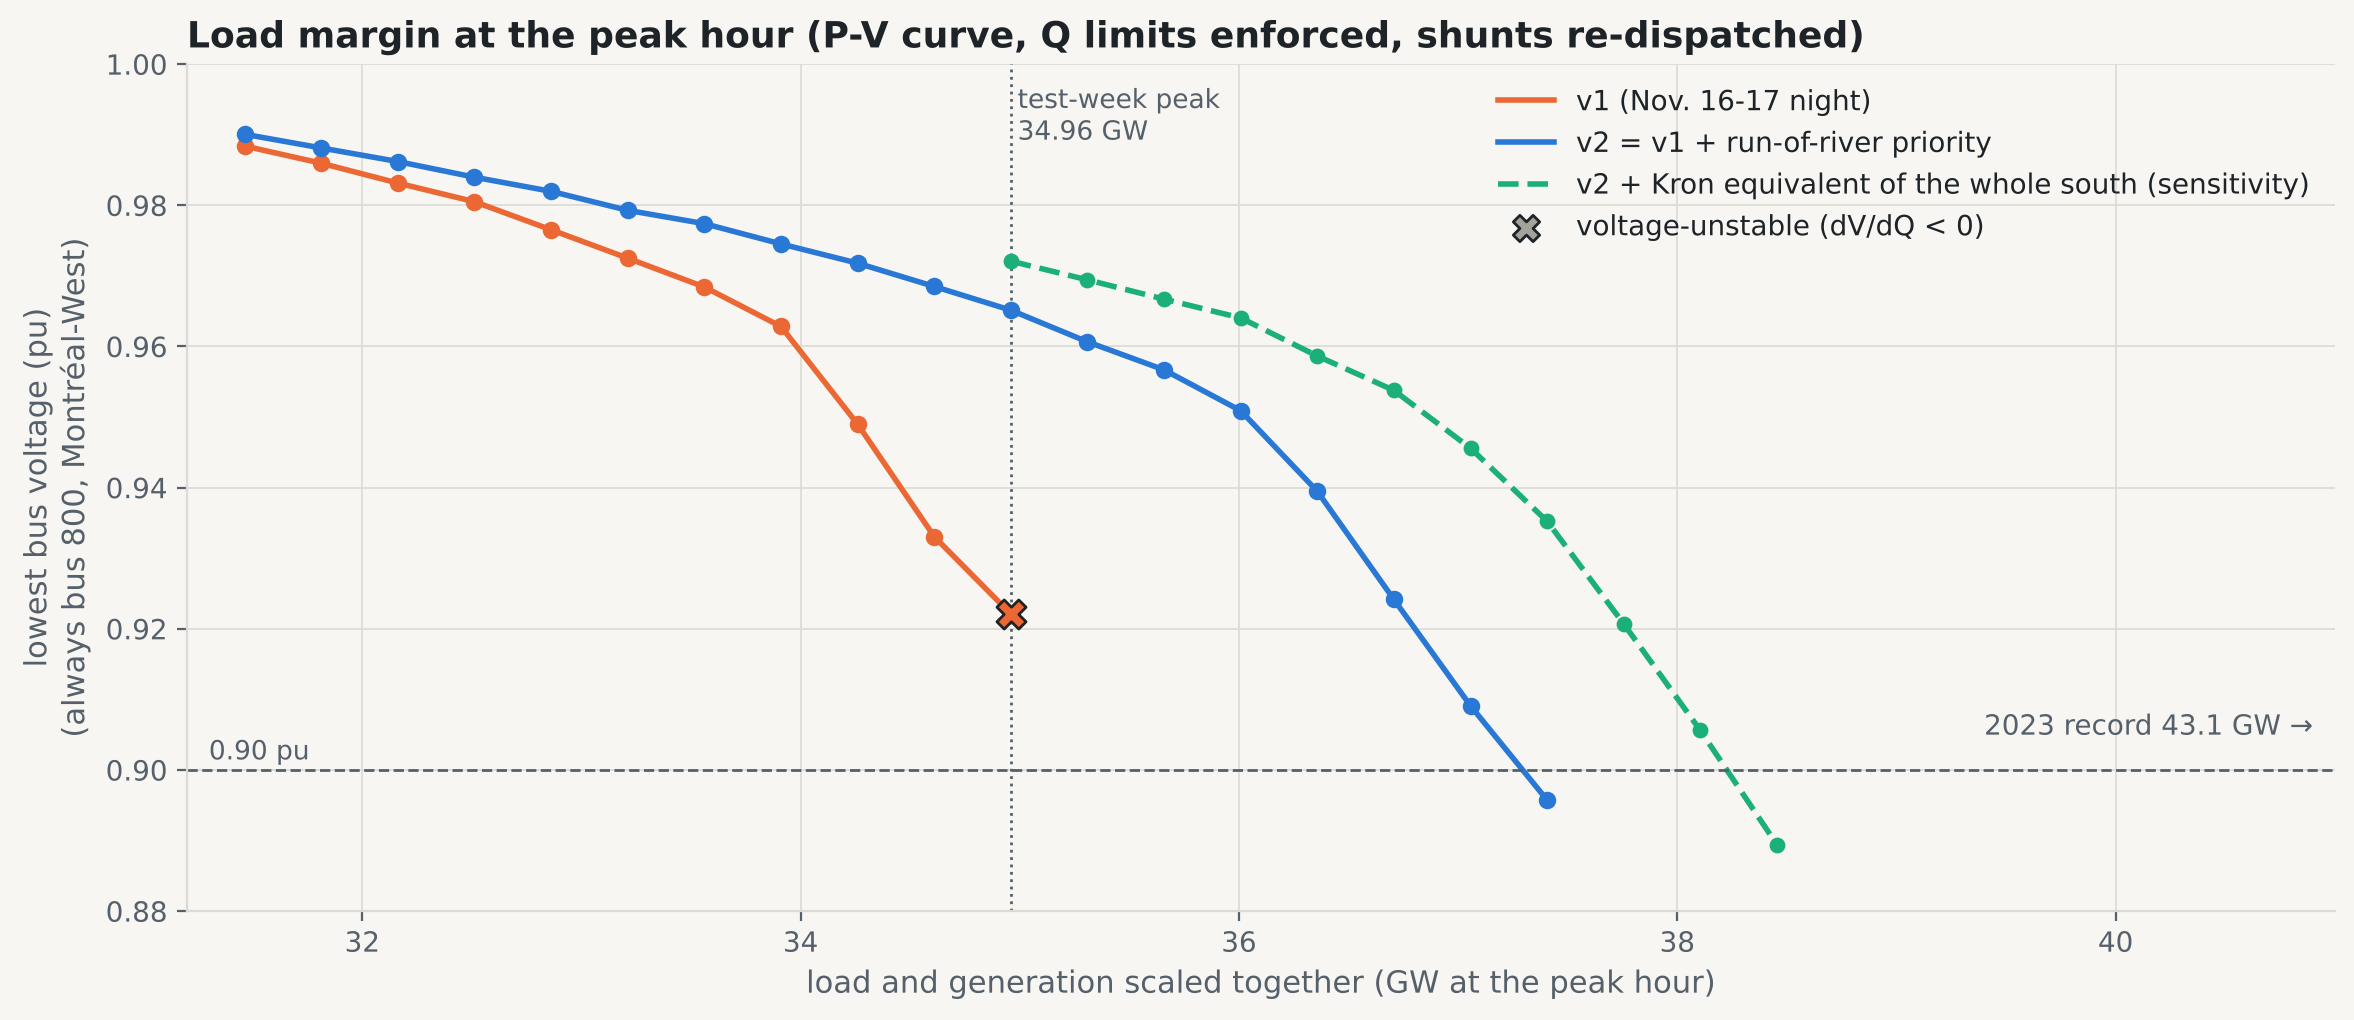

In [11]:
F.fig_pv(d["pv"], d["pv_kron"]);
pv = d["pv"]
for case in ("v1", "v2"):
    s = pv[(pv.case == case) & pv.solved.astype(bool) & pv.stable.fillna(False).astype(bool) & (pv.lam >= 1)]
    print(f"{case}: last stable point at the peak: " + (f"λ = {s.lam.max():.2f} ({s.GW.max():.1f} GW)" if len(s) else "none (the peak itself is unstable)"))
k = d["pv_kron"]; ks = k[k.stable.astype(bool)]
print(f"v2 + Kron equivalent of the whole southern < 315 kV network (Québec buses only): λ = {ks.lam.max():.2f} ({ks.GW.max():.1f} GW)")
print(f"Real grid: {F.RECORD_GW:.1f} GW on Feb. 3, 2023 → λ ≥ {F.RECORD_GW / 34.959:.2f}")

**Reading.** v2 tolerates +7 % (37.4 GW) before the voltage becomes unstable (+6 % if we also require V ≥ 0.90 pu, or if only running machines provide reactive power); restoring the southern sub-transmission paths as Kron equivalents gives +10 % (38.5 GW). The real grid carried at least +23 %. The binding constraint is **voltage**, always first at bus 800 (Montréal-West), not thermal ratings. Candidate explanations, in our order of belief:
- **reactive support in the south is under-represented** (capacitor banks at load substations are an assumption; Duvernay's three synchronous condensers have an assumed rating);
- **losses are probably counted twice**: if HQ's hourly demand already includes transmission losses, our AC model adds 1.2-1.5 GW of losses on top (on top of v2, correcting this and spreading losses over the running plants instead of the James Bay slack gives λ ≈ 1.11; stability not yet checked);
- **loads are attached to the nearest ≥ 315 kV bus as the crow flies**, which concentrates Montréal's load on a few buses.

## 7. Challenged assumptions: what we corrected, confirmed, or still assume

**One assumption at a time.** Each line below rebuilds the whole week (LOPF + 168 h of AC) with a single assumption removed or changed, on the v1 dispatch. This is our design-alternatives table (the peak margins in it are computed with Q limits but before the V-Q stability test): it shows what each correction buys and that the three variants which look *better* than v1 do so for the wrong reasons (doubled Churchill lines, 70 % series compensation where HQ uses 35-40 %, or a line operated beyond its stability limit).

,within Q limits,in 0.90-1.10,in 0.95-1.05,V min,V max,peak margin λ (before the stability test)
variant,,,,,,
v1 (reference),168,168,165,0.922,1.035,1.000
without E1 (Mercator lengths kept),159,158,130,0.937,1.118,NaN
without E2 (Churchill Falls lines doubled),168,168,168,0.952,1.040,1.050
without E2b (no Kron equivalents),168,165,155,0.885,1.034,1.005
E2b with Saguenay only (no Montréal),167,164,155,0.887,1.034,1.010
without E3 (Nathan's circuit fix),166,166,165,0.932,1.033,1.015
E4 at 70 % instead of 40 %,168,168,168,0.956,1.033,1.060
without E4 (no series compensation),164,164,162,0.934,1.033,1.000
without E5 (no 40° stability cap),168,168,168,0.965,1.035,1.055


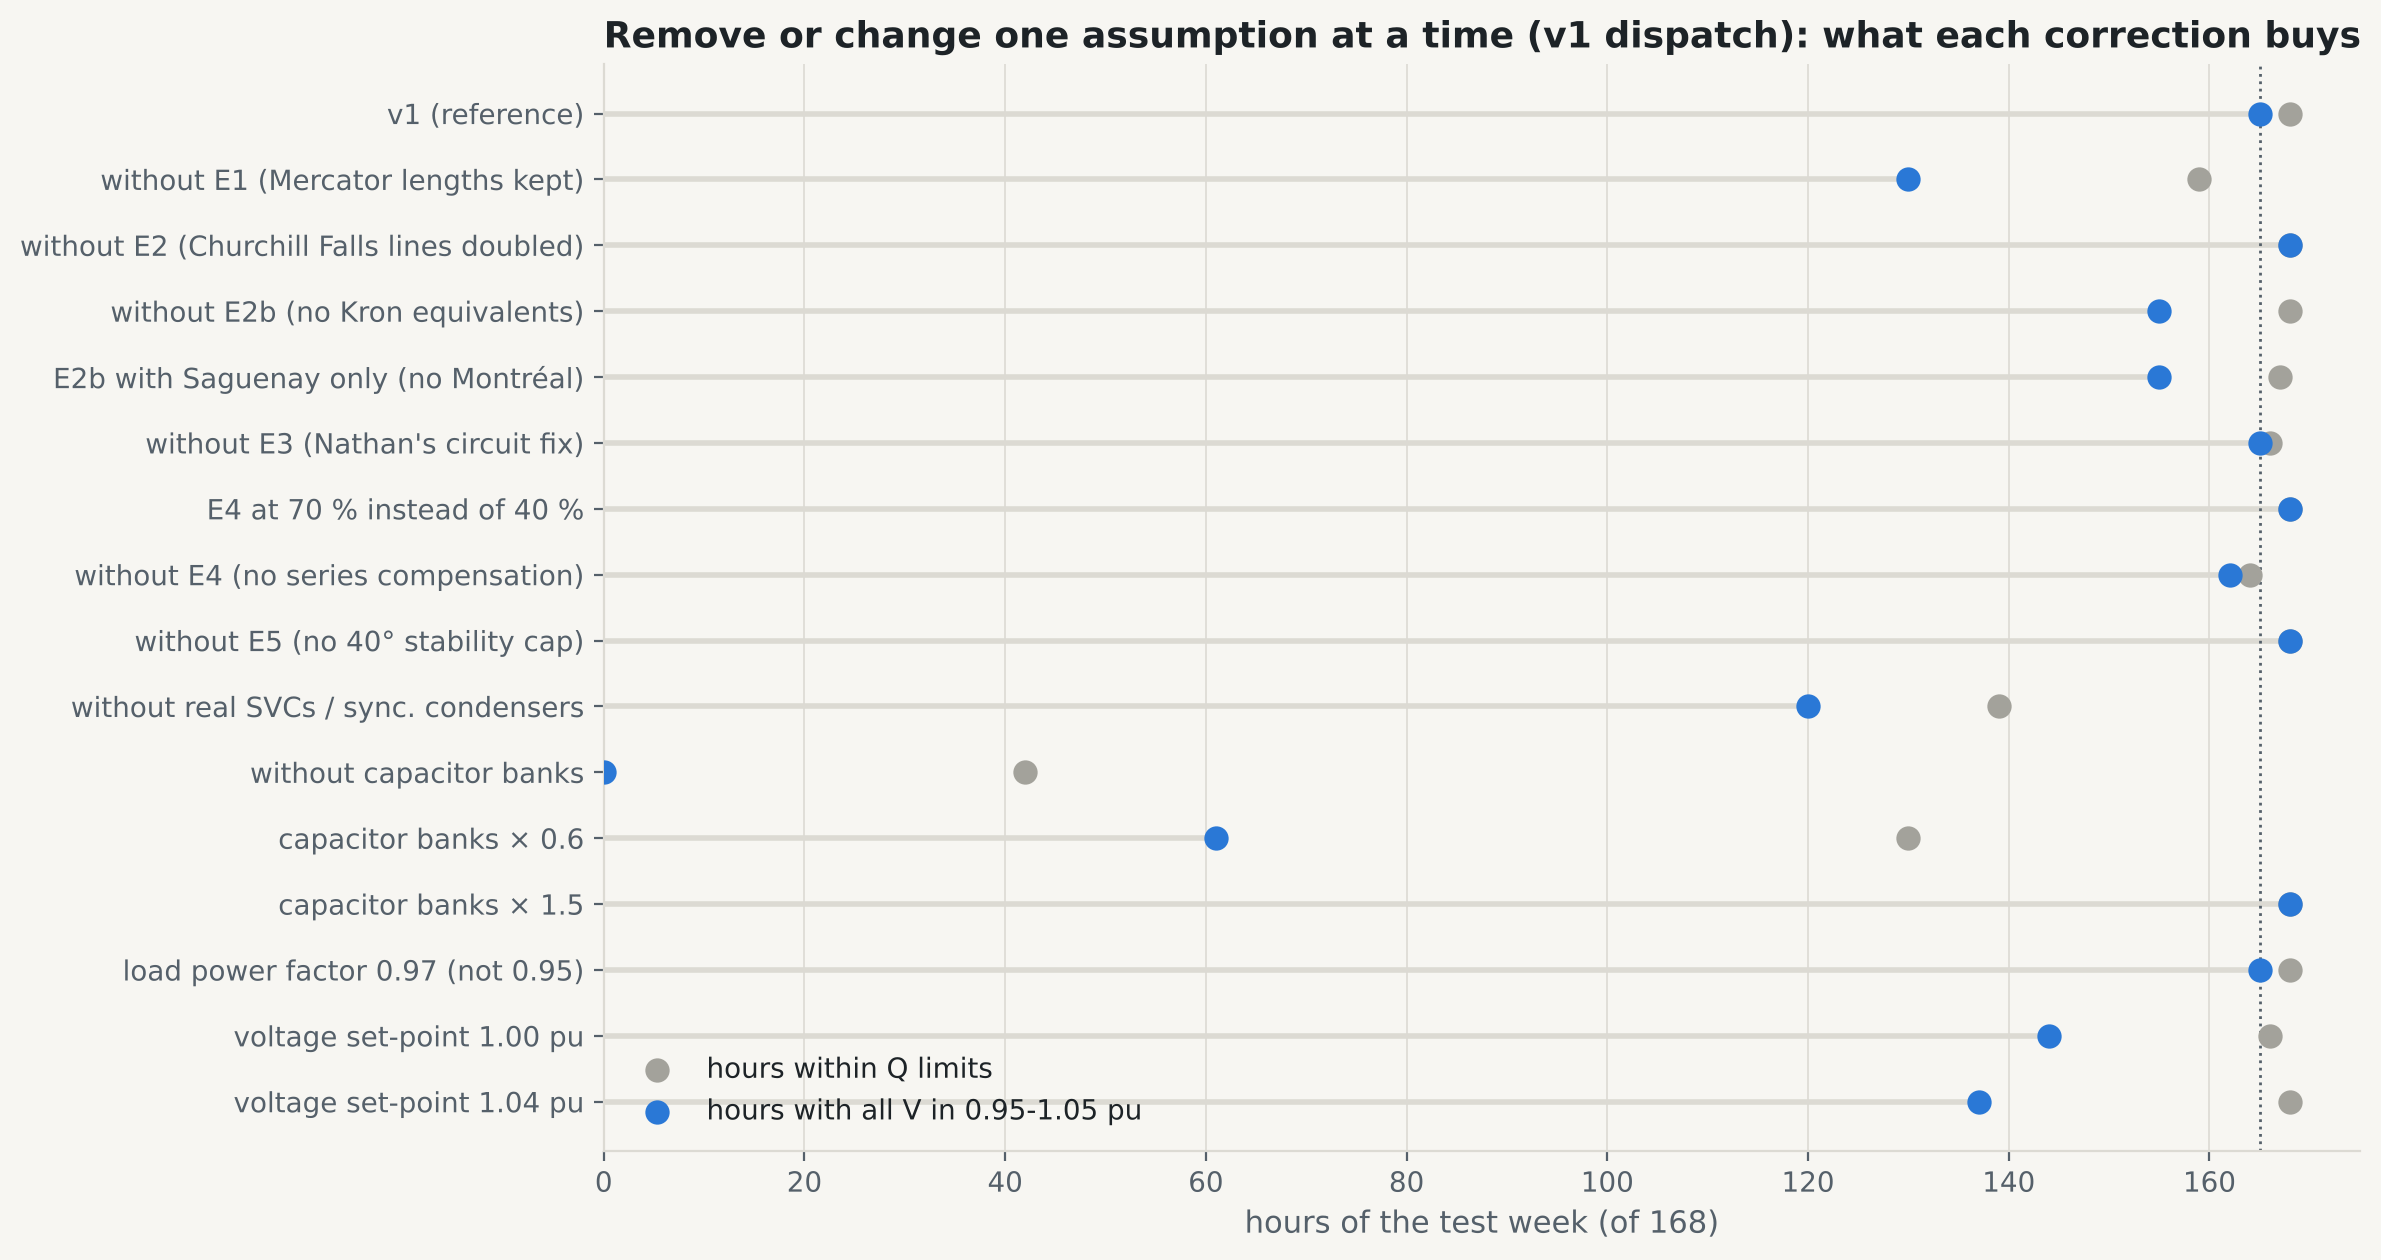

In [12]:
F.fig_sensitivity(d["sens"]);
display(F.sens_table(d["sens"]).set_index("variant").rename(columns={"peak margin λ": "peak margin λ (before the stability test)"}))

| Assumption | Status | Evidence | What would settle it |
|---|---|---|---|
| Line lengths from OSM (Web Mercator) | **corrected** (E1) | km in our model vs HQ: 735 kV 12,696 vs 12,581 (incl. ~690 km in Labrador); 315 kV 5,281 vs 5,509 | — |
| Churchill Falls corridor, 6 circuits | **corrected** (E2) | same corridor added twice | — |
| < 315 kV network deleted by the reduction | **partly corrected** (Kron, 2 regions) | +3 % margin with the whole south | real substation transformations |
| Nathan's circuit counts (E3) | **questioned** | adds 2,684 circuit-km: 735 kV total +17 % above HQ; night reactors above HQ's installed 25.5 GVAr | HQ line-by-line circuit list |
| 70 % series compensation on 15 lines | **replaced** by 40 % on 8 real corridors | Régie D-2016-122 | list of the 32 series banks |
| Unlimited reactive power | **replaced** by Q limits + real SVCs/condensers | Régie R-3712-2009 table of SVCs | condenser ratings at Duvernay, Abitibi, Manicouagan |
| Q capability from installed capacity (even when idle) | **still assumed**, made harmless at the peak by v2 | v2 peak converges with Q from running units only | unit commitment data |
| Capacitor banks = Q of peak load (10.8 GVAr) | **still assumed**, the most influential one | without them only 42/168 h within Q limits; ×1.5 → λ 1.115 (before the stability test) | Mvar per substation from HQ |
| Hydro all at zero cost (degenerate LOPF) | **corrected** (run-of-river priority) | peak unstable in v1, stable in v2 | historical 2022 dispatch by plant |
| All AC losses produced by the slack (LG-2) | **still assumed** | LG-2 above its installed capacity 101 h in v1, 3 h in v2 | distributed slack in the AC loop |
| Hourly demand excludes losses | **doubtful** | HQ transmission figures are published "with losses" | definition of the demand dataset |
| Loads attached as the crow flies to ≥ 315 kV buses | **still assumed** | below 315 kV, a 69 kV bus would carry 851 MW on one line rated $V^2/x$ = 835 MW | load per substation |
| Line types below 315 kV at 50 Hz | **corrected** where used (×1.2) | $\sqrt{xb}/\ell$ test | HQ line table at 60 Hz |

## 8. Exploratory: going below 315 kV

You asked us to go as low in voltage as feasible. We put back the real < 315 kV network of `elec_full.nc` under the v2 model (597 buses down to 69 kV, 716 lines, 133 transformers; same corrections) and returned each load to its original bus. Result:
- **raw, it does not converge**, even with unlimited reactive power, beyond 25 % of the peak load;
- the cause is mostly the **load allocation**, not the network: the regional demand-scaling step puts loads of several hundred MW on small buses (17 buses below 315 kV carry more than 300 MW; one 69 kV bus carries 851 MW at the end of a single line whose static limit $V^2/x$ is 835 MW);
- after leaving 7.2 GW of the 35 GW at the 315 kV buses (the physically impossible loads, plus 36 buses that collapse first when load is ramped up), the peak converges **with Q limits and is voltage-stable**, but 8 to 11 buses (161/230 kV lines in Abitibi-Témiscamingue without reactors, one 120 kV bus) stay outside 0.90-1.10 pu, and there is no load margin.

,hour,GW,newton,machines outside Q limits,machines at a Q limit,v_min,v_max,buses outside 0.90-1.10,buses outside 0.95-1.05,v_min_315_735,v_max_315_735,buses with dV/dQ<0,losses (MW)
0,2022-01-03 17:00:00,35.0,True,0,21,0.890,1.103,8,57,0.923,1.042,0,2394
1,2022-01-03 18:00:00,34.5,True,0,21,0.904,1.104,10,49,0.940,1.042,0,2314
2,2022-01-04 10:00:00,34.2,True,0,19,0.911,1.104,10,43,0.948,1.041,0,2276
3,2022-01-02 16:00:00,30.2,True,0,16,0.947,1.108,10,40,0.977,1.046,0,1715
4,2022-01-05 04:00:00,27.4,True,0,16,0.963,1.112,10,43,0.985,1.048,0,1422
5,2022-01-01 03:00:00,22.0,True,0,16,0.979,1.125,11,53,0.987,1.053,0,960


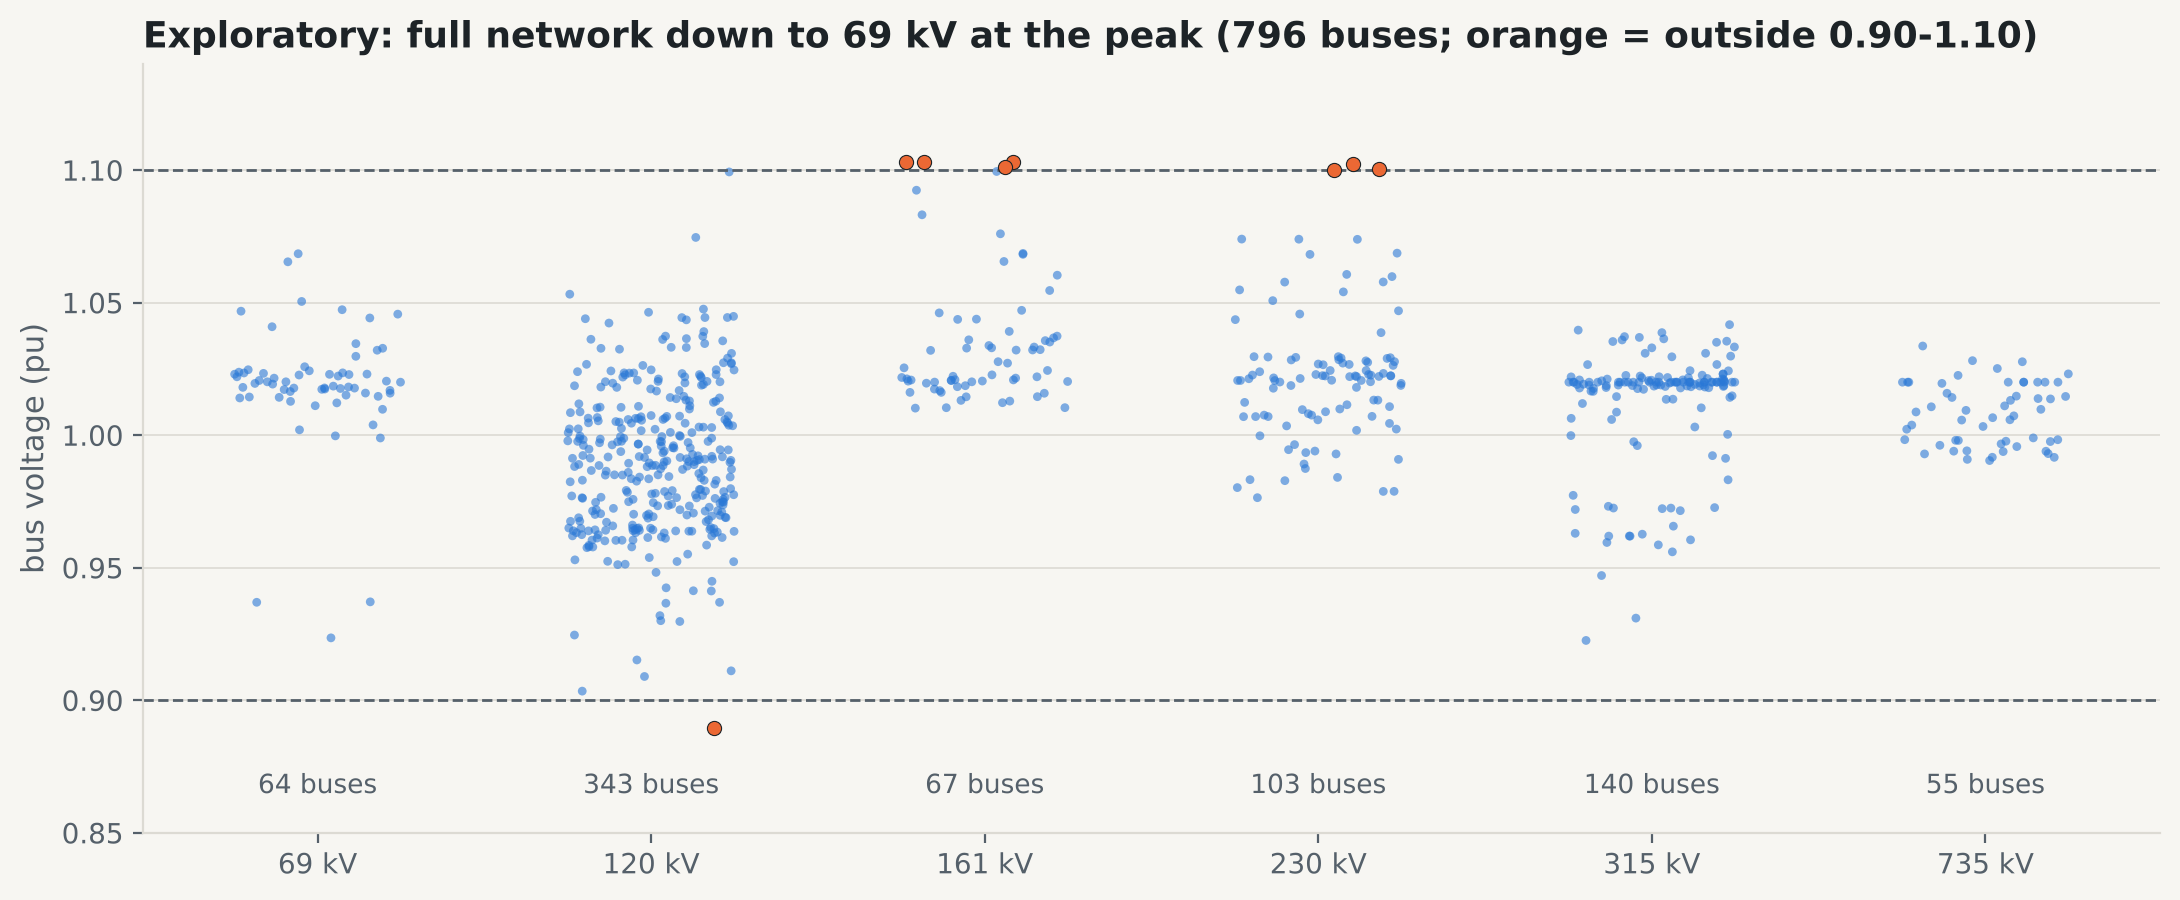

In [13]:
F.fig_full_network(d["full"]);
display(d["full_hours"].rename(columns={"heure": "hour", "regs_hors_limites": "machines outside Q limits", "regs_en_butee": "machines at a Q limit",
                                        "bus_hors_090_110": "buses outside 0.90-1.10", "bus_hors_095_105": "buses outside 0.95-1.05",
                                        "bus_dVdQ_negatif": "buses with dV/dQ<0", "pertes_MW": "losses (MW)"}).drop(columns=["s"], errors="ignore"))

**Conclusion.** Below 315 kV, the network data is usable but the **load data is not**: we need a defensible allocation of demand to substations before a 69-230 kV model makes sense. Until then, Kron equivalents of the passive < 315 kV network are the better choice for the 315 kV model.

## 9. Discussion

### 9.1 Is a model without exact data useful? What is it for?
Hydro-Québec does not publish its network model, and we will never have exact impedances, compensation settings or substation loads. We think the model is still useful, **for the right questions**:

- **Relative and comparative questions, not absolute predictions.** *Which corridors, when lost under ice or wind, cause the most load shedding? Which mitigation (hardening, reactive support, series compensation, redispatch) reduces it most? How does that ranking change under climate scenarios?* A ranking is much more robust to parameter error than a number of MW shed.
- **Mechanisms.** The model already tells us something non-obvious: at the winter peak, the binding limit is **voltage in the Montréal area**, not line thermal capacity; and the dispatch of southern run-of-river plants matters for voltage stability. These are statements about the structure of the system.
- **An open, documented benchmark.** There is no public model of the Québec grid (Nathan's motivation). Research on cascading failures and resilience relies on synthetic grids (IEEE 39-bus, the Texas 2000-bus ACTIVSg case) precisely because real data are confidential; a Québec-scale model with real topology, real generation and calibrated aggregates sits between the two.
- **Uncertainty, rather than precision, is the honest framing — and it connects directly to your research.** Unknown parameters (capacitor banks per substation, condenser ratings, load allocation, Q capability) can be treated as **random inputs**. A PCE surrogate and Sobol indices would then tell us *which unknowns actually drive the resilience metrics* — i.e. which data are worth asking Hydro-Québec for — and give the metrics as distributions rather than point values. This is the same machinery as your group's PCE-based resilience assessment with AC-CFM (Gerkis & Wang, 2025, on IEEE 39-bus).

What it cannot do: predict which tower fails, or give the real MW shed on a real date. And there is an ethical side: a list of the grid's critical corridors should be published only in aggregated form.

**Conditions for the model to be credible:** every assumption documented, every aggregate checked against public numbers (km per voltage level, installed capacity, peak demand, losses, the 2023 record), several solvers agreeing, and sensitivity analyses on everything we had to assume.

### 9.2 Why not just add infinite SVCs everywhere?
With unlimited reactive power at every bus, every bus becomes a PV bus at its set-point, the reactive equations disappear, and only the active-power equations remain: $P_i = \sum_k |V_i||V_k|(G_{ik}\cos\theta_{ik}+B_{ik}\sin\theta_{ik})$ with all $|V| = 1$. Newton then **almost always converges** — but:
1. **Not always.** If the active power that must cross a cut exceeds its static limit ($\sum V^2/x \cdot \sin\theta$, at most $V^2/x$ for a single line), there is no solution at any voltage. In Nathan's 315 kV model the Romaine pocket had to export 696 MW over line 3360 whose $V^2/x$ was 673 MW: no amount of reactive power fixes that.
2. **It answers the wrong question.** The reactive power "needed" is enormous and unrealistic (Nathan's 735 kV model: 22-51 GVAr absorbed by generators, 8 GVAr at a 73 MW plant). It removes exactly the phenomenon we found to be binding — voltage collapse at the peak — and an AC-CFM cascade on such a model would never see under-voltage load shedding, so resilience would be overestimated.
3. **It hides design information.** *Where* extra reactive support would help (e.g. one more SVC near Montréal-West) is a legitimate design alternative — but it must be sized and tested **with** Q limits, by comparing load margins and load shed.

So: infinite Q makes the model a DC power flow with losses. Useful as a sanity check of active-power transfers, not as a resilience model.

### 9.3 Questions for you
1. Is **v2** (315 kV + Kron equivalents, 168/168 hours on five criteria, +7 % margin) an acceptable base case for the AC-CFM phase, or should we first close part of the margin gap?
2. Do you agree with **voltage stability** ($\partial V/\partial Q > 0$) being part of our definition of a converged case?
3. **Data:** could your group, IREQ or Hydro-Québec contacts give us, even in aggregated form, the Mvar of capacitor banks and reactors per region, the series-compensation list, or demand per substation?
4. Should we report the **Web Mercator length issue** to Nathan and upstream to PyPSA-Earth (with credit to Nathan's model)?
5. Is it worth treating the unknown parameters as **random inputs (PCE / Sobol)** in our project, in line with your group's methods?
6. Going below 315 kV: given that the blocker is load allocation, should we spend time there, or stay at 315 kV + Kron for the cascade study?
7. Can we use your **extended AC-CFM** (Gerkis & Wang, 2025)?

## 10. Next steps: rebuild it ourselves, step by step, from OpenStreetMap

What we have now is a map of the problems and their fixes, found largely with an AI assistant. The next phase is to **rebuild the model by hand**, understanding and documenting every step, so that no error survives and every team member can defend every number. v2 serves as the reference against which each rebuilt step is compared.

| Phase | Content | Check that closes the phase |
|---|---|---|
| **0** (by Nov. 19) | Progress Report #3 (incl. ethics & equity); freeze v2 as the reference; share findings with Nathan | team review of this notebook |
| **1. Topology** | our own OSM extraction for Québec (Overpass): lines, substations, voltages; **geodesic lengths**; bus merging rule written down | km per voltage level within ±10 % of HQ's table (735: 12,581 · 315: 5,509 · 230: 3,252 · 161: 2,128 · 120: 6,969 km); circuit counts per corridor |
| **2. Electrical parameters** | 60 Hz parameters from the HQ line table; transformers per substation; series compensation from Régie documents; our own $Y_{bus}$ | our $Y_{bus}$ = PyPSA's to $10^{-10}$; $\sqrt{xb}$ per km ≈ $\omega/c$ |
| **3. Generation and load** | HQ plant list with unit counts (for Q capability); demand per region → substations with a written allocation rule and a **feasibility check** (no bus load above a fraction of its local transfer capacity) | installed capacity, 2022 peak, regional totals |
| **4. Dispatch and AC** | LOPF with run-of-river priority (or historical 2022 dispatch), AC with Q limits, stability criterion, load margin; distributed slack; demand with/without losses | three solvers agree; five criteria 168/168; margin compared with the 2023 record |
| **5. Resilience** | export to AC-CFM; N-1/N-2 screening; climate hazards (freezing rain, wind) through fragility curves; metrics (load shed, EDNS, CVaR); mitigation alternatives; UQ on unknown parameters | design report (mid-project report, Dec. 4) |

**Working rules** (already in our repository's `CLAUDE.local.md`): one assumption at a time, each with its source and its effect; nothing written in `network/networks_current/`; a logbook entry per session; every result checked by a second solver.

## Appendix: reproducibility

| File | Content |
|---|---|
| `../reseau_315kv/reseau315.py` | every correction step, our Newton-Raphson, MATPOWER export, validation |
| `../reseau_315kv/Reseau_315kV_converge.ipynb` | the detailed (French) notebook of v1, with the physics of each step |
| `../revue_fable/RAPPORT.md` | the critical review (French) and all its scripts |
| `make_results.py` | builds v2 and writes `data/` (~3 min) |
| `figs.py` | all figures of this notebook and of the slides |
| `data/quebec_315kv_v2_peak.m` | MATPOWER case of the v2 peak hour (stable), for AC-CFM |
| `data/reseau_315kv_v2.nc` | the v2 network (PyPSA) |

Environment: PyPSA 1.3.0, HiGHS, pandas 2.3 or 3.1, pandapower 3.x for validation. Nothing is written in `network/networks_current/`.

Sources: Hydro-Québec, *Nos équipements* (km of lines per voltage level) and record peak of 43,124 MW (Feb. 3, 2023); PyPSA-Earth configuration documentation (`distance_crs`); Régie de l'énergie R-3712-2009 (SVCs), D-2016-122 (series compensation); Gao, Morison & Kundur, *Voltage stability evaluation using modal analysis*, IEEE Trans. Power Syst., 1992; Gerkis & Wang, *Efficient probabilistic assessment of power system resilience using the polynomial chaos expansion method with enhanced stability*, arXiv:2501.09857 (2025).